# 09 · Summary of results

Collects the result tables written by notebooks 03–08 into one overview.
Two protocols are involved, so the panels are not directly comparable:

- **pixels / radiomics** (notebooks 03–04): all 737 AD and CN subjects,
  evaluated once on a stratified 30% test set (222 subjects);
- **TDA** (notebooks 06–08): a balanced subset of 212 subjects, evaluated by
  repeated 5-fold cross-validation (mean ± std over 50 folds).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from adni_tau.paths import TABLES_DIR, save_figure, save_table

pix = pd.read_csv(TABLES_DIR / "03_pixel_pca_results.csv")
rad = pd.read_csv(TABLES_DIR / "04_radiomics_ad_cn_results.csv")
tda_07 = pd.read_csv(TABLES_DIR / "07_point_cloud_cv.csv")
tda_08 = pd.read_csv(TABLES_DIR / "08_3d_and_quantile_cv.csv")
multi = pd.read_csv(TABLES_DIR / "05_multiclass_results.csv")

## AD vs CN: best model per feature family and view

In [2]:
rows = []
for view in ["axial", "coronal", "sagittal"]:
    p = pix[pix["view"] == view].sort_values("cv_balanced_accuracy", ascending=False).iloc[0]
    rows.append({"features": "pixels + PCA", "view": view, "model": p["model"], "balanced_accuracy": p["balanced_accuracy"], "roc_auc": p["roc_auc"]})
    for mask, label in (("brain", "radiomics (whole brain)"), ("ROI", "radiomics (PCA/ANOVA ROI)")):
        r = rad[(rad["view"] == view) & (rad["mask"] == mask)].sort_values("cv_balanced_accuracy", ascending=False).iloc[0]
        rows.append({"features": label, "view": view, "model": r["model"], "balanced_accuracy": r["balanced_accuracy"], "roc_auc": r["roc_auc"]})
ad_cn = pd.DataFrame(rows)
save_table(ad_cn, "09_ad_cn_best_by_family")
ad_cn.round(3)

,features,view,model,balanced_accuracy,roc_auc
0,pixels + PCA,axial,PCA + logistic regression,0.794,0.900
1,radiomics (whole brain),axial,RBF SVM,0.710,0.805
2,radiomics (PCA/ANOVA ROI),axial,logistic regression,0.660,0.748
3,pixels + PCA,coronal,PCA + logistic regression,0.849,0.918
4,radiomics (whole brain),coronal,logistic regression,0.830,0.916
5,radiomics (PCA/ANOVA ROI),coronal,logistic regression,0.903,0.948
6,pixels + PCA,sagittal,PCA + logistic regression,0.778,0.843
7,radiomics (whole brain),sagittal,logistic regression,0.738,0.814
8,radiomics (PCA/ANOVA ROI),sagittal,logistic regression,0.840,0.929


Models are chosen by **cross-validated** balanced accuracy on the training
set, never by test performance.

## TDA: cross-validated balanced accuracy

In [3]:
lower = pd.read_csv(TABLES_DIR / "06_lower_star_cv.csv").iloc[0]
tda = pd.concat(
    [
        pd.DataFrame([{"pipeline": "lower-star", "mean": lower["cv_balanced_accuracy_mean"], "std": lower["cv_balanced_accuracy_std"]}]),
        tda_08[tda_08["pipeline"] == "quantile lower_star"].assign(pipeline="lower-star, quantile threshold")[["pipeline", "cv_balanced_accuracy_mean", "cv_balanced_accuracy_std"]].set_axis(["pipeline", "mean", "std"], axis=1),
        tda_07.assign(pipeline=tda_07["filtration"].map({"alpha": "alpha", "delaunaycech": "Delaunay-Čech", "rips": "Vietoris-Rips", "weighted_rips": "weighted Rips"}))[["pipeline", "cv_balanced_accuracy_mean", "cv_balanced_accuracy_std"]].set_axis(["pipeline", "mean", "std"], axis=1),
        tda_08[tda_08["pipeline"] == "3D alpha"][["pipeline", "cv_balanced_accuracy_mean", "cv_balanced_accuracy_std"]].set_axis(["pipeline", "mean", "std"], axis=1),
    ],
    ignore_index=True,
).sort_values("mean")
save_table(tda, "09_tda_cv_summary")
tda.round(3)

,pipeline,mean,std
0,lower-star,0.668,0.070
2,alpha,0.672,0.055
3,Delaunay-Čech,0.688,0.058
6,3D alpha,0.704,0.051
1,"lower-star, quantile threshold",0.720,0.059
4,Vietoris-Rips,0.740,0.054
5,weighted Rips,0.774,0.057


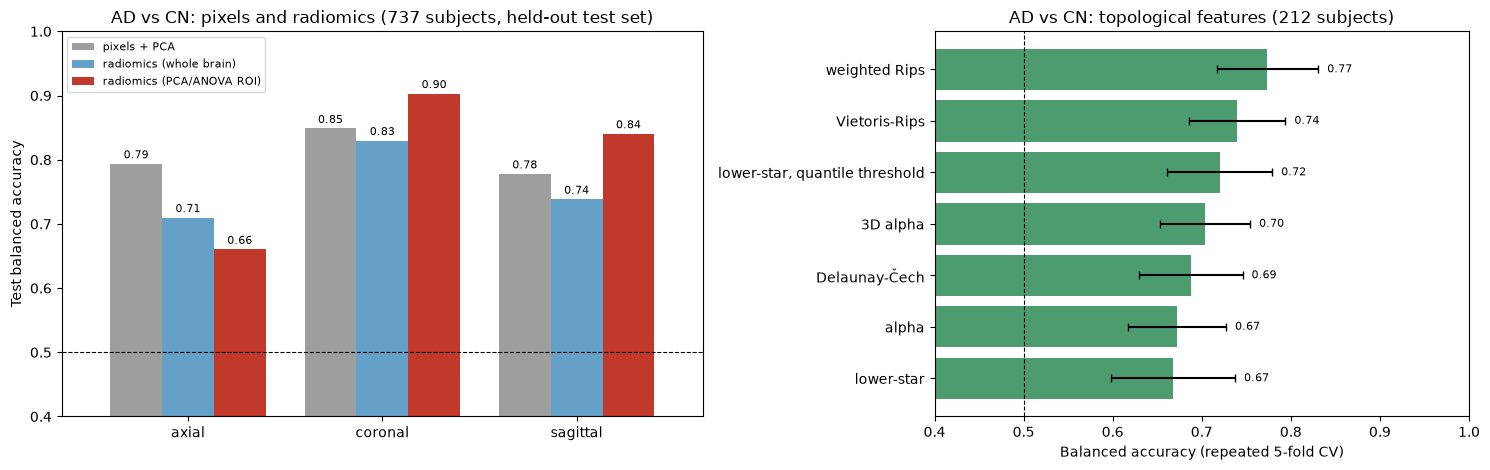

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})

pivot = ad_cn.pivot(index="view", columns="features", values="balanced_accuracy")[["pixels + PCA", "radiomics (whole brain)", "radiomics (PCA/ANOVA ROI)"]]
pivot.plot.bar(ax=axes[0], rot=0, color=["#9e9e9e", "#64a0c8", "#c0392b"], width=0.8)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.2f", fontsize=8, padding=2)
axes[0].axhline(0.5, color="k", linestyle="--", linewidth=0.8)
axes[0].set(ylim=(0.4, 1.0), ylabel="Test balanced accuracy", xlabel="", title="AD vs CN: pixels and radiomics (737 subjects, held-out test set)")
axes[0].legend(fontsize=8, loc="upper left")

axes[1].barh(tda["pipeline"], tda["mean"], xerr=tda["std"], color="#2e8b57", alpha=0.85, capsize=3)
for y, (m, s) in enumerate(zip(tda["mean"], tda["std"])):
    axes[1].text(m + s + 0.01, y, f"{m:.2f}", va="center", fontsize=8)
axes[1].axvline(0.5, color="k", linestyle="--", linewidth=0.8)
axes[1].set(xlim=(0.4, 1.0), xlabel="Balanced accuracy (repeated 5-fold CV)", title="AD vs CN: topological features (212 subjects)")
fig.tight_layout()
save_figure(fig, "00_summary")

## Three classes (CN / MCI / AD)

In [5]:
# Best model per feature set chosen by CV macro-F1 (late fusion has a single model).
best3 = multi.sort_values("cv_macro_f1", ascending=False, na_position="first").groupby("features", sort=False).head(1)
best3[["features", "model", "macro_f1", "balanced_accuracy", "roc_auc"]].round(3)

,features,model,macro_f1,balanced_accuracy,roc_auc
12,late fusion,random forest + random forest + random forest,0.556,0.552,0.719
9,early fusion,logistic regression,0.474,0.510,0.691
5,coronal,random forest,0.493,0.492,0.684
8,sagittal,random forest,0.485,0.500,0.717
2,axial,random forest,0.424,0.426,0.625
